---   
 <img align="left" width="75" height="75"  src="https://upload.wikimedia.org/wikipedia/en/c/c8/University_of_the_Punjab_logo.png">

<h1 align="center">Department of Data Science</h1>

---
<h3><div align="right">Instructor: Muhammad Arif Butt, Ph.D.</div></h3>    

<h1 align="center">Lec-05: A Hello to Google Colab and Kaggle</h1>

<div align="center">
  <a href="https://colab.research.google.com/github/arifpucit/Generative-and-Agentic-AI/blob/main/Notebooks/Lec_05_(A_Hello_to_Google_Colab).ipynb" target="_blank">
    <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab">
  </a>
  &nbsp;
  <a href="https://kaggle.com/kernels/welcome?src=https://github.com/arifpucit/Generative-and-Agentic-AI/blob/main/Notebooks/Lec_05_(A_Hello_to_Google_Colab).ipynb" target="_blank">
    <img src="https://kaggle.com/static/images/open-in-kaggle.svg" alt="Open in Kaggle">
  </a>
</div>

> **One Notebook, Two Platforms**
> - **Section 2 is written for Google Colab.** Open this notebook with the **Open in Colab** badge above and run the cells of Section 2 there.
> - **Section 3 is written for Kaggle.** Open it with the **Open in Kaggle** badge and run the cells of Section 3 there.
> - **Run the next cell first**, on either platform: it shows where the notebook runs and the hardware you got. A free Colab T4 runtime has 2 CPU cores, ~12.7 GB RAM and one Tesla T4 (15 GB); Kaggle with **GPU T4 × 2** has 4 CPU cores, ~29 GB RAM and two T4s.
> - Every other code cell starts with the same `Running on:` check, so you can see which platform ran it.

In [1]:
import os
import shutil
import psutil
import torch

# 1. Which platform? Kaggle has a /kaggle/working folder, Colab has a /content folder
if os.path.isdir("/kaggle/working"):
    where = "Kaggle"
elif os.path.isdir("/content"):
    where = "Google Colab"
else:
    where = "Local machine"
print("Running on:     ", where)
print("Current folder: ", os.getcwd())

# 2. CPU and RAM
cpu_cores = psutil.cpu_count(logical=True)
ram = psutil.virtual_memory()
ram_gb = ram.total / 1024**3
print("CPU cores:      ", cpu_cores)
print(f"RAM:             {ram_gb:.1f} GB")

# 3. Free disk space in the current folder
disk = shutil.disk_usage(".")
free_gb = disk.free / 1024**3
print(f"Free disk:       {free_gb:.1f} GB")

# 4. GPUs
if torch.cuda.is_available():
    gpu_count = torch.cuda.device_count()
    print("GPUs:           ", gpu_count)
    for i in range(gpu_count):
        name = torch.cuda.get_device_name(i)
        properties = torch.cuda.get_device_properties(i)
        memory_gb = properties.total_memory / 1024**3
        print(f"  GPU {i}: {name}, {memory_gb:.1f} GB")
else:
    print("GPUs:            none (Colab: Runtime -> Change runtime type, Kaggle: Settings -> Accelerator)")

Running on:      Google Colab
Current folder:  /content
CPU cores:       2
RAM:             12.7 GB
Free disk:       112.5 GB
GPUs:            1
  GPU 0: Tesla T4, 14.6 GB


# Learning agenda of this notebook
1. **An Overview of Platforms for Running ML/DL Code**
2. **Google Colab (run this section on Colab)**
    - a. What Colab Gives You: Free and Paid Tiers
    - b. What You Can Do on Google Colab
    - c. Getting Started: Your Google Account and a Colab Session
    - d. Opening a Notebook in Colab (GitHub, Badge, Google Drive)
    - e. Saving Your API Keys and a Hello-World Call to OpenAI
    - f. Mounting Google Drive and Reading Your Own Files
    - g. Hands-on: Download Small Datasets on Colab (MNIST, Rotten Tomatoes, Palmer Penguins)
    - h. Troubleshooting: "CUDA is required but not available"
3. **Kaggle Notebooks (run this section on Kaggle)**
    - a. What Kaggle Gives You for Free
    - b. Creating Your Kaggle Account
    - c. A Kaggle Session, Step by Step
    - d. Opening This Notebook on Kaggle
    - e. Saving Your API Keys and a Hello-World Call to OpenAI
    - f. Hands-on: Download Small Datasets on Kaggle (Fashion-MNIST, Titanic, SMS Spam)
4. **Google Colab vs Kaggle: Compute and Memory, Free and Paid Tiers**

# <span style='background :lightgreen' >1. An Overview of Platforms for Running ML/DL Code</span>

<div align="center"><img src="https://github.com/arifpucit/Generative-and-Agentic-AI/blob/main/images/colab-kaggle-01.png?raw=1" width="1500"></div>

| Category        | [Google Colab](https://colab.research.google.com) | [Kaggle](https://www.kaggle.com/code) | [RunPod](https://www.runpod.io) | [Vast.ai](https://vast.ai) | [Lambda Labs](https://lambdalabs.com) | [Google Cloud](https://cloud.google.com) | [AWS](https://aws.amazon.com) |
|-----------------|--------------------------------------------------|---------------------------------------|--------------------------------|----------------------------|--------------------------------------|------------------------------------------|--------------------------------|
| **Description** | Free Jupyter Notebook service with GPU/TPU access. Great for students & beginners. **Gemini** integration enables features like “Generate Code,” “Explain Error,” “Chat in Notebook.” | Free Jupyter notebooks from Google's data-science community, with free GPUs/TPUs and thousands of ready-to-use datasets and competitions. | On-demand GPU cloud with flexible hourly pricing. | Peer-to-peer GPU rentals with very low costs. | Premium GPU provider optimized for ML projects. | Enterprise cloud with scalable GPU/TPU options. | Industry-standard cloud with wide ML ecosystem. |
| **Pricing (approx.)** | Free tier (T4, limited); Pro: \$9.99/mo; Pro+: \$49.99/mo | Free (weekly GPU quota); no paid plan | RTX 4090 (24 GB RAM): \$0.34/hr; H100: \$1.99/hr; A100: ~\$2.25/hr | Spot GPUs from \$0.05/hr (consumer) up to ~\$2/hr (A100/H100) | RTX 4090: \$0.60/hr; A100: \$2.5–3.5/hr | A100: ~\$2.5/hr; H100: ~\$4–5/hr (spot up to 90% off) | A100: ~\$3.1/hr; H100: ~\$6–7/hr (spot cheaper) |
| **Key Features** | ML libs pre-installed, Google Drive sync, collaborative, no setup | 2 × T4 or P100 GPU, 29 GB RAM, datasets attach as folders, versioned notebooks | Multiple GPU types, Docker templates, persistent storage, scaling | Consumer + pro GPUs, flexible rentals, community-driven pricing | Optimized ML stack, high uptime, professional support | Global infra, TPU/GPU access, Vertex AI, GCP services | Broad GPU range, SageMaker ML, enterprise-grade security |
| **Pros ✅**     | Free tier, quick start, beginner-friendly, good for tutorials | More free RAM and GPU memory than Colab, datasets one click away, community notebooks to learn from | Low hourly rates, easy to scale, user-friendly | Cheapest option, large GPU variety, very flexible | Reliable, ML-optimized envs, pro support | Enterprise reliability, global infra, advanced ML services | Mature ecosystem, best docs, wide integrations |
| **Cons ❌**     | Limited runtime, GPU shortages, not for production | Weekly GPU quota, phone verification needed, 20-minute idle time-out | No free tier, setup needed, costs add up hourly | Variable reliability, limited support, setup overhead | Expensive, overkill for beginners, best for pros | Complex pricing, steep learning curve, costly small-scale | Highest costs, complex billing, steep learning curve |

> **Prices change.** The figures above are indicative only — always check each provider's own pricing page before committing to a plan. Colab's current tiers are at https://colab.research.google.com/signup and Kaggle's limits at https://www.kaggle.com/docs/notebooks

# <span style='background :lightgreen' >2. Google Colab</span>

<h3 align="center"><div class="alert alert-success" style="margin: 20px">Google Colab is a free, cloud-based Python and machine-learning workspace (accessible with any Google account) that provides a ready-to-use environment with CPUs, ~12–13 GB RAM, and access to GPUs like the NVIDIA T4 when available, along with preinstalled libraries such as Keras, PyTorch, TensorFlow, NumPy, and more.</div></h3>


## a. What Colab Gives You: Free and Paid Tiers
- On the free tier, Google Colab provides the following:
    - CPU (always available): 2 vCPU and ~12.7 GB RAM
    - GPU (limited, usually an NVIDIA T4 with 15 GB GPU memory)
    - TPU (limited)
    - Sessions of **at most 12 hours**; idle runtimes are stopped earlier. Colab does not publish exact limits, and they change with demand.
- Besides the free tier, Colab has paid options: https://colab.research.google.com/signup
  - **Pay As You Go:** \\$9.99 for 100 compute units (\$49.99 for 500). Compute units are credits you spend while using premium GPUs (L4, A100, H100), TPUs (v2-8, v5e-1, v6e-1) or High-RAM runtimes. Unused compute units expire after 90 days.
  - **Colab Pro** (\$9.99 per month): 100 compute units every month, faster GPUs, High-RAM runtimes.
  - **Colab Pro+** (\$49.99 per month): 600 compute units every month, plus background execution for up to 24 hours.
  - **Colab Enterprise** (pay for what you use, inside Google Cloud).
  - Paid **Google AI plans** (for example Google AI Pro) now also include a monthly allotment of Colab compute units.
- As a rule of thumb, the cheapest paid GPU (a T4) costs roughly \$0.1–0.2 per hour. Colab shows the current rate (compute units per hour) in the **Resources** panel.
- Section 4 compares these tiers with Kaggle.

>- **GPUs** (Graphics Processing Units) are primarily used for Graphics rendering, but now we use them for General-purpose parallel compute. A GPU may have thousands of small cores and is excellent at SIMD-style parallelism. Some examples are NVIDIA (T4, V100, A100, H100) and AMD (MI250). They work well for training, fine-tuning and inference tasks. However, they use high power and are not purpose-built for matrix math only.
>- **TPUs** (Tensor Processing Units) are designed by Google specifically for ML. Some examples are TPU v2, v3, v4, v5e. They are excellent for large-scale training, however, have limited support for custom CUDA ops.
>- **LPUs** (Language Processing Units) are designed specifically for LLM inference by Groq (Groq LPU). They are mostly used for inference and not suitable for training or fine-tuning.

## b. What You Can Do on Google Colab
- Create, upload, download, and share Jupyter notebooks entirely in the browser.
- Import notebooks from Google Drive and save your work back to Drive automatically.
- Load notebooks from GitHub and publish your own notebooks back to your GitHub repositories.
- Install and use any Python library (PyTorch, TensorFlow, Transformers, etc.) instantly.
- Import datasets from Kaggle or any external URL for training or analysis.
- Colab lets you connect to a local runtime. This allows you to execute code on your local hardware.
- Hugging Face Integration Inside Colab
    - Access the Hugging Face Hub directly using huggingface_hub commands.
    - Clone, test, or create Hugging Face Spaces (Streamlit, Gradio, FastAPI apps) from Colab.
    - Download pretrained models for inference, fine-tuning, or experimentation.
    - Upload your own models (LoRA, full models, tokenizers) to your Hugging Face profile.
    - Load Hugging Face datasets instantly for NLP, vision, and multimodal tasks.
    - Push training outputs (models / logs / datasets) to Hugging Face with a single command.

## c. Getting Started: Your Google Account and a Colab Session
- **Account:** Colab uses your Google account; there is no separate Colab account. If you do not have one yet, create it at https://accounts.google.com/signup (any Gmail address works).
- **Open Colab** at https://colab.research.google.com and sign in with that account.

<div align="center"><img src="https://github.com/arifpucit/Generative-and-Agentic-AI/blob/main/images/colab-kaggle-02.png?raw=1" width="1500"></div>

- **Open Colab through Google Drive:** Go to https://drive.google.com/ → New → More → Google Colaboratory (This will create a new notebook in your Google Drive and open it inside Colab)
- To use the free GPU: **Runtime → Change runtime type → T4 GPU → Save**. Then run the hardware cell at the top of the notebook to see the machine you got.

## d. Opening a Notebook in Colab (GitHub, Badge, Google Drive)
**Method 1: Use the Google Colab interface (Open from the GitHub tab)**
- Go to [https://colab.research.google.com](https://colab.research.google.com)
- Click on the **“GitHub”** tab on the left side of the dialog
- Enter GitHub repository name `https://github.com/arifpucit/Generative-and-Agentic-AI` and Colab will display all `.ipynb` files it can find. Click the notebook you want → Click **Open**

**Method 2: Use the “Open in Colab” badge / link**
- For this course, notebooks hosted at https://github.com/arifpucit/Generative-and-Agentic-AI, I am using a badge under the Lecture title in every notebook file and clicking that will open the notebook from GitHub repository to your Google Colab for execution.
- An example badge link looks like this:

```html
<a href="https://colab.research.google.com/github/USERNAME/REPO/blob/main/notebook.ipynb" target="_blank">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab">
</a>
```

**Method 3: Open a notebook stored in your Google Drive**
- From Colab: go to https://colab.research.google.com → click the **"Google Drive"** tab → authorize access → select the `.ipynb` file → **Open**.
- From Google Drive: find your `.ipynb` file → right-click → **Open with** → **Google Colaboratory**.
  - If "Google Colaboratory" doesn’t appear: click **"Connect more apps"** → search for **"Colaboratory"** → click **Install**.

> A notebook opened from GitHub is a temporary copy. Use **File → Save a copy in Drive** (or **Save a copy in GitHub**) to keep your changes.

## e. Saving Your API Keys and a Hello-World Call to OpenAI
- **No OpenAI API key yet?** Create one at https://platform.openai.com/api-keys → **Create new secret key**. API calls are paid, so your OpenAI account needs some billing credit.
- **Where to Save the API Keys when working in Google Colab?**
- Never directly copy paste the secret key inside the code cell. If you do so, make sure that you do not share the notebook with anyone.
- When working inside Google Colab, save your secrets by clicking the key icon on the side panel on the left and add all your secret keys over there, e.g., the OpenAI API key.
    - In the name field put `OPENAI_API_KEY`
    - In the value field put your actual token: `sk-proj-xyz...`
    - Ensure the notebook access switch is turned ON.
- API Keys in Colab “Secrets” / Environment Variables only live in the RAM of that runtime, or your browser session, or your account secrets storage (if using the UI).
- Anyone opening/downloading your notebook (hosted in your public GitHub repo or your Google Drive) can see the code, markdown, outputs and notebook metadata.
- They CANNOT see environment variables created at runtime and secrets stored through the Colab UI.
- Before running the following code cell (that accesses the secret `OPENAI_API_KEY`), you must first set your own OpenAI API Key as mentioned above. You'll need to do this on each of the course Colab notebook files.
- The cell then makes a **hello-world call** to OpenAI's `gpt-5-mini` model. It is a reasoning model, so the answer can take a few seconds.

In [2]:
# NOTE: This cell runs ONLY inside Google Colab.
# `google.colab` is provided by the Colab runtime and cannot be installed locally,
# so running this on your own machine raises ModuleNotFoundError. That is expected.
# This code will run only if the notebook is running on colab
import os

# Which platform? Kaggle has a /kaggle/working folder, Colab has a /content folder
if os.path.isdir("/kaggle/working"):
    where = "Kaggle"
elif os.path.isdir("/content"):
    where = "Google Colab"
else:
    where = "Local machine"
print("Running on:     ", where)
print("Current folder: ", os.getcwd())

from google.colab import userdata  # google.colab is a Python module available only inside Google Colab and userdata is a utility that allows you to securely store and retrieve sensitive information (like API keys).
from openai import OpenAI

# Store your key in Colab's secrets (left sidebar > key icon) and access it using userdata.get() method
openai_api_key = userdata.get( 'OPENAI_API_KEY') # Fetch the value associated with OPENAI_API_KEY from Google Colab’s secret storage and assign it to a variable so I can use it in my code.

# Create client
client = OpenAI(base_url="https://api.openai.com/v1", api_key=openai_api_key)

# Responses API call with list-based input
response = client.responses.create(
                                model="gpt-5-mini",
                                #input= "What is the color of the sky? Tell me in a single line."   # 'input' replaces 'messages' for the Responses API and can be a simple string or can be a list specifying the developer and user role
                                input=[{"role": "developer", "content": "Always answer in a short and clear way."}, {"role": "user", "content": "Who is Ada Lovelace?"}])

# Extract and print the output text
print(response.output_text)

Running on:      Google Colab
Current folder:  /content
Ada Lovelace (Augusta Ada King, Countess of Lovelace; 1815–1852) was an English mathematician and writer best known for her work on Charles Babbage’s proposed Analytical Engine.

Key points:
- Translated an 1842 paper by Luigi Menabrea about the Engine and added extensive notes (published 1843).  
- Her “Note G” includes an algorithm for the Engine to compute Bernoulli numbers, often cited as the first computer program.  
- She foresaw that such machines could manipulate symbols and do more than arithmetic—an early vision of modern computing.  
- Daughter of the poet Lord Byron.  
- Died in 1852; widely regarded as the first computer programmer and an important figure in computing history.


## f. Mounting Google Drive and Reading Your Own Files
- Everything in `/content` is deleted when the runtime ends. To keep data files and trained models, **mount your Google Drive**: it then appears as the folder `/content/drive/MyDrive`.
- Run the following cell and allow Colab to access your Drive:

In [3]:
# NOTE: This cell runs ONLY inside Google Colab.
# `google.colab` is provided by the Colab runtime and cannot be installed locally,
# so running this on your own machine raises ModuleNotFoundError. That is expected.
import os

# Which platform? Kaggle has a /kaggle/working folder, Colab has a /content folder
if os.path.isdir("/kaggle/working"):
    where = "Kaggle"
elif os.path.isdir("/content"):
    where = "Google Colab"
else:
    where = "Local machine"
print("Running on:     ", where)
print("Current folder: ", os.getcwd())

from google.colab import drive
drive.mount('/content/drive')

Running on:      Google Colab
Current folder:  /content
Mounted at /content/drive


- The next cell creates a folder `genai-course` in **your** Google Drive, writes a small CSV file into it (the first rows of the classic *advertising* dataset), and reads it back.
- The file is still in your Drive after the runtime ends. To read your own data, upload the file to Drive and change `file_path`.

In [4]:
# NOTE: Runs only in Colab, AFTER the drive.mount() cell above has been executed.
# The path /content/drive/... does not exist on a local machine.
import os

# Which platform? Kaggle has a /kaggle/working folder, Colab has a /content folder
if os.path.isdir("/kaggle/working"):
    where = "Kaggle"
elif os.path.isdir("/content"):
    where = "Google Colab"
else:
    where = "Local machine"
print("Running on:     ", where)
print("Current folder: ", os.getcwd())

import pandas as pd

# A folder in YOUR Google Drive for this course
folder = "/content/drive/MyDrive/genai-course"
os.makedirs(folder, exist_ok=True)                 # create it if it does not exist yet

# A tiny table: advertising budgets (in $1000s) and the sales they produced
data = pd.DataFrame({
    "TV":        [230.1, 44.5, 17.2],
    "Radio":     [37.8, 39.3, 45.9],
    "Newspaper": [69.2, 45.1, 69.3],
    "Sales":     [22.1, 10.4, 9.3],
})

# Write it into your Drive ...
file_path = folder + "/advertising_sample.csv"
data.to_csv(file_path, index=False)
print("Saved:", file_path)

# ... and read it back
df = pd.read_csv(file_path)
df.head()

Running on:      Google Colab
Current folder:  /content
Saved: /content/drive/MyDrive/genai-course/advertising_sample.csv


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3


## g. Hands-on: Download Small Datasets on Colab

<div align="center"><img src="https://github.com/arifpucit/Generative-and-Agentic-AI/blob/main/images/colab-kaggle-05.png?raw=1" width="1500"></div>

- Three small, famous datasets, one per cell: **MNIST** (images), **Rotten Tomatoes** (text) and **Palmer Penguins** (a table). Each cell downloads the data and shows a few examples; no model is trained here.
- The files land in the Colab runtime (`/content/data` for torchvision and the penguins CSV, a cache folder for Hugging Face) and are deleted when the runtime ends. Running a cell again in the same runtime reuses them.
- Section 3f downloads three other datasets on Kaggle: Fashion-MNIST, Titanic and SMS Spam.

### Example C1: MNIST Handwritten Digits (Images) with torchvision
- **What it contains:** 70,000 handwritten digits, 60,000 for training and 10,000 for testing. Each one is a 28 × 28 grey image with a label from 0 to 9. The digits were written by US Census Bureau employees and high-school students; Yann LeCun, Corinna Cortes and Christopher Burges put the dataset together in 1998 from older NIST data.
- **What it is used for:** it is the "hello world" of deep learning: the first image classifier most people train, and a quick test bed for new ideas. Even a small neural network gets most digits right, and a convolutional network gets more than 99% right.
- **Download:** `torchvision.datasets.MNIST` downloads four compressed files (about 12 MB) into `data/MNIST/`.

Running on:      Google Colab
Current folder:  /content


100%|██████████| 9.91M/9.91M [00:00<00:00, 14.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 347kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.21MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.94MB/s]


Training images: 60000
Test images:     10000
Shape of one image: torch.Size([1, 28, 28])
Its label:          5


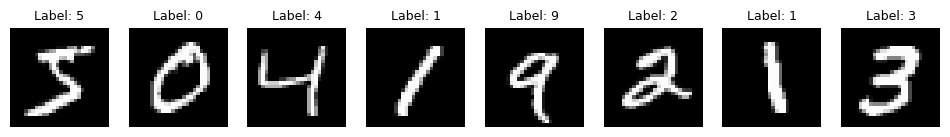

In [5]:
import os

# Which platform? Kaggle has a /kaggle/working folder, Colab has a /content folder
if os.path.isdir("/kaggle/working"):
    where = "Kaggle"
elif os.path.isdir("/content"):
    where = "Google Colab"
else:
    where = "Local machine"
print("Running on:     ", where)
print("Current folder: ", os.getcwd())

from torchvision import datasets
from torchvision import transforms
import matplotlib.pyplot as plt

to_tensor = transforms.ToTensor()      # turns a picture into a tensor of numbers between 0 and 1

train_data = datasets.MNIST(
    root="data",            # folder to save the files in
    train=True,             # the 60,000 training images
    download=True,          # download only if the files are not there yet
    transform=to_tensor)    # convert every image to a tensor

test_data = datasets.MNIST(
    root="data",
    train=False,            # the 10,000 test images
    download=True,
    transform=to_tensor)

print("Training images:", len(train_data))
print("Test images:    ", len(test_data))

# Look at the first training image
image, label = train_data[0]
print("Shape of one image:", image.shape)     # [1, 28, 28] = 1 grey channel, 28 x 28 pixels
print("Its label:         ", label)

# Show the first 8 training images with their labels
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i in range(8):
    image, label = train_data[i]
    ax = axes[i]
    ax.imshow(image[0], cmap="gray")          # image[0] drops the channel dimension
    ax.set_title(f"Label: {label}", fontsize=9)
    ax.axis("off")
plt.show()

### Example C2: Rotten Tomatoes Movie Reviews (Text) with Hugging Face `datasets`
- **What it contains:** 10,662 one-sentence movie reviews from the Rotten Tomatoes website, exactly half positive and half negative. Each row has a `text` and a `label` (**0 = negative**, **1 = positive**). The data comes split into 8,530 training, 1,066 validation and 1,066 test sentences. Bo Pang and Lillian Lee (Cornell University) collected it in 2005. The text is already lower-case and split into words, so you see a space before every comma and full stop.
- **What it is used for:** sentiment analysis, i.e. deciding whether a text is positive or negative. Because every review is a single short sentence, it is a quick dataset for a first text classifier and for fine-tuning or testing a small language model.
- **Download:** `load_dataset()` downloads three Parquet files from the Hugging Face Hub (less than 1 MB) and caches them in `~/.cache/huggingface`.

In [6]:
import os

# Which platform? Kaggle has a /kaggle/working folder, Colab has a /content folder
if os.path.isdir("/kaggle/working"):
    where = "Kaggle"
elif os.path.isdir("/content"):
    where = "Google Colab"
else:
    where = "Local machine"
print("Running on:     ", where)
print("Current folder: ", os.getcwd())

from datasets import load_dataset

reviews = load_dataset("cornell-movie-review-data/rotten_tomatoes")
print(reviews)

# The first and the last review of the training split
first = reviews["train"][0]
last = reviews["train"][-1]
print("Label:", first["label"], " Text:", first["text"])
print("Label:", last["label"], " Text:", last["text"])
print("(0 = negative, 1 = positive)")

Running on:      Google Colab
Current folder:  /content


README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/8530 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8530
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
})
Label: 1  Text: the rock is destined to be the 21st century's new " conan " and that he's going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .
Label: 0  Text: things really get weird , though not particularly scary : the movie is all portent and no content .
(0 = negative, 1 = positive)


### Example C3: Palmer Penguins (a Table) from a CSV File on the Web
- **What it contains:** measurements of 344 penguins of three species (152 Adelie, 124 Gentoo, 68 Chinstrap) from three islands (Biscoe, Dream, Torgersen) in the Palmer Archipelago, Antarctica. The 7 columns are `species`, `island`, `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g` and `sex`. Dr. Kristen Gorman collected the data at Palmer Station between 2007 and 2009.
- **What it is used for:** it is a modern replacement for the Iris flowers dataset: predict the species from the measurements (classification), group the penguins without labels (clustering), and draw your first plots. It also has a few missing values (2 penguins without measurements, 11 without `sex`), so it is good for practising data cleaning.
- **Download:** a plain CSV file of about 13 KB from seaborn's dataset collection on GitHub. `pd.read_csv()` can read a file straight from a URL; the cell then saves a copy as `data/penguins.csv`.

In [7]:
import os

# Which platform? Kaggle has a /kaggle/working folder, Colab has a /content folder
if os.path.isdir("/kaggle/working"):
    where = "Kaggle"
elif os.path.isdir("/content"):
    where = "Google Colab"
else:
    where = "Local machine"
print("Running on:     ", where)
print("Current folder: ", os.getcwd())

import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
penguins = pd.read_csv(url)                     # download the CSV and read it into a table

# Save a copy in the data folder of the runtime
os.makedirs("data", exist_ok=True)
penguins.to_csv("data/penguins.csv", index=False)

print("Rows, columns:", penguins.shape)
print(penguins["species"].value_counts())        # how many penguins of each species
penguins.head()

Running on:      Google Colab
Current folder:  /content
Rows, columns: (344, 7)
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


## h. Troubleshooting: "CUDA is required but not available"
In the middle of running a Colab, you might get a Runtime error saying CUDA is required but not available for bitsandbytes. On the free tier, this actually happens because Google has switched out your Colab runtime, perhaps because Google Colab was too busy. The solution is:
>- **Runtime** menu >> Disconnect and delete runtime
>- Reload the colab from fresh and Edit menu >> Clear All Outputs
>- Connect to a new T4 using the button at the top right
>- Select "View resources" from the menu on the top right to confirm you have a GPU
>- Rerun the cells in the colab

# <span style='background :lightgreen' >3. Kaggle Notebooks</span>

<h3 align="center"><div class="alert alert-success" style="margin: 20px">Kaggle (owned by Google) is the largest online community for data science and machine learning. Its free Notebooks service runs Jupyter in the browser on 4 CPU cores with 29–30 GB RAM, lets you add free GPUs (2 × NVIDIA T4 or 1 × P100) or a TPU v3-8, and puts thousands of datasets one click away.</div></h3>

## a. What Kaggle Gives You for Free
- **Hardware** per session (from Kaggle's [technical specifications](https://www.kaggle.com/docs/notebooks)):

| Accelerator (Settings → Accelerator) | GPU / TPU | CPU cores | RAM | Session limit |
|---|---|---|---|---|
| None (CPU only) | — | 4 | 30 GB | 12 hours |
| **GPU T4 × 2** (recommended for this course) | 2 × NVIDIA T4, 15 GB each | 4 | 29 GB | 12 hours |
| GPU P100 | 1 × NVIDIA P100, 16 GB | 4 | 29 GB | 12 hours |
| TPU v3-8 | 8 TPU cores | 96 | 330 GB | 9 hours |

- **Weekly quota:** GPU and TPU time is rationed per week (commonly about 30 GPU hours and 20 TPU hours). Your remaining hours are shown in your Kaggle **Settings → Quotas**. CPU-only sessions do not use the quota, so switch the accelerator off when you do not need it.
- **Disk:** up to 20 GB in `/kaggle/working` is saved with each notebook version. Everything else is deleted when the session ends.
- **Idle time-out:** an interactive session ends after 20 minutes without activity.
- **No paid plan:** Kaggle is free. Colab Pro and Pro+ subscribers can link their account (**File → Link to Colab**) to get 15 or 30 extra GPU hours per week.
- **Besides notebooks:** Datasets, Models, Competitions and free Learn courses, all usable from a notebook.

> **Why GPU T4 × 2?** It is the same T4 GPU that Colab gives you, so code written on Colab runs on Kaggle unchanged. You get two of them, but simple code uses only the first one.

## b. Creating Your Kaggle Account
1. Go to https://www.kaggle.com and click **Register** (top right).
2. Sign up with your Google account (the easiest way) or with an email address and a password.
3. Choose a username and accept the terms.
4. **Verify your phone number:** click your profile picture → **Settings** → **Phone verification**, enter your number and the code you receive by SMS. Without it you cannot use GPUs, TPUs or the Internet inside a notebook: the **Internet** switch stays greyed out.
5. On the same Settings page, **Quotas** shows how many free GPU and TPU hours you have left this week.

## c. A Kaggle Session, Step by Step

<div align="center"><img src="https://github.com/arifpucit/Generative-and-Agentic-AI/blob/main/images/colab-kaggle-03.png?raw=1" width="1500"></div>

- **Quick Save** stores the notebook exactly as you see it. **Save & Run All** starts a fresh session, runs every cell from top to bottom in the background (you can close the browser), and keeps the outputs and the files in `/kaggle/working` as the version's **Output**.

## d. Opening This Notebook on Kaggle
**Method 1: Use the “Open in Kaggle” badge**
- Click the **Open in Kaggle** badge under the lecture title at the top of this notebook and sign in. Kaggle imports the notebook from GitHub into a new notebook in your account.
- An example badge link looks like this:

```html
<a href="https://kaggle.com/kernels/welcome?src=https://github.com/USERNAME/REPO/blob/main/notebook.ipynb" target="_blank">
  <img src="https://kaggle.com/static/images/open-in-kaggle.svg" alt="Open in Kaggle">
</a>
```

**Method 2: Import the notebook yourself**
- Go to https://www.kaggle.com/code → **+ New Notebook**.
- **File → Import Notebook**, then upload the `.ipynb` file (download it from GitHub first) or paste the link of the notebook:
  - https://github.com/arifpucit/Generative-and-Agentic-AI/blob/main/Notebooks/Lec_05_(A_Hello_to_Google_Colab).ipynb

**Then, in the Settings panel on the right:**
- **Accelerator → GPU T4 × 2** (the session restarts; you may wait in a queue when Kaggle is busy).
- **Internet → On**, so that the code can download datasets and install packages.

> **Check the Internet switch every time.** A notebook opened through the **Open in Kaggle** badge can start with **Internet Off**. Then no cell can download a dataset, `!pip install` fails, and even reading a secret fails. If the switch is greyed out, verify your phone number first (Section 3b).

- Run the hardware cell at the top of the notebook to see the machine you got.

In [1]:
import os
import shutil
import psutil
import torch

# 1. Which platform? Kaggle has a /kaggle/working folder, Colab has a /content folder
if os.path.isdir("/kaggle/working"):
    where = "Kaggle"
elif os.path.isdir("/content"):
    where = "Google Colab"
else:
    where = "Local machine"
print("Running on:     ", where)
print("Current folder: ", os.getcwd())

# 2. CPU and RAM
cpu_cores = psutil.cpu_count(logical=True)
ram = psutil.virtual_memory()
ram_gb = ram.total / 1024**3
print("CPU cores:      ", cpu_cores)
print(f"RAM:             {ram_gb:.1f} GB")

# 3. Free disk space in the current folder
disk = shutil.disk_usage(".")
free_gb = disk.free / 1024**3
print(f"Free disk:       {free_gb:.1f} GB")

# 4. GPUs
if torch.cuda.is_available():
    gpu_count = torch.cuda.device_count()
    print("GPUs:           ", gpu_count)
    for i in range(gpu_count):
        name = torch.cuda.get_device_name(i)
        properties = torch.cuda.get_device_properties(i)
        memory_gb = properties.total_memory / 1024**3
        print(f"  GPU {i}: {name}, {memory_gb:.1f} GB")
else:
    print("GPUs:            none (Colab: Runtime -> Change runtime type, Kaggle: Settings -> Accelerator)")

Running on:      Kaggle
Current folder:  /kaggle/working
CPU cores:       4
RAM:             31.3 GB
Free disk:       19.5 GB
GPUs:            none (Colab: Runtime -> Change runtime type, Kaggle: Settings -> Accelerator)


## e. Saving Your API Keys and a Hello-World Call to OpenAI
- Kaggle has its own secret store, just like Colab's key icon:
    - In the notebook editor, open the **Add-ons** menu → **Secrets** → **Add Secret**.
    - Label: `OPENAI_API_KEY`, Value: your actual token `sk-proj-xyz...`
    - Tick the checkbox next to the secret to **attach** it to this notebook. A secret that exists in your account but is not ticked for this notebook cannot be read.
- Secrets are stored with your Kaggle account. They are **not** copied when you share or publish the notebook.
- **Reading a secret needs Internet.** `get_secret()` fetches the key from Kaggle's servers. With Internet Off it fails with `Temporary failure in name resolution` and `ConnectionError: Connection error trying to communicate with service`, even though the secret exists. Turn **Settings → Internet → On** and run the cell again. The first lines of the cell check this for you.
- **The label must match exactly.** The cell asks for `"OPENAI_API_KEY"`; a secret labelled `openai_api_key` is a different secret.
- The cell below is the Kaggle version of the OpenAI cell in Section 2e. Only the Internet check and the lines that read the key are different.

In [3]:
# NOTE: This cell runs ONLY inside a Kaggle notebook (with Internet turned On).
# `kaggle_secrets` is provided by the Kaggle runtime, so on Colab or on your own
# machine it raises ModuleNotFoundError. That is expected.
# If Kaggle says "No module named 'openai'", run this line first:  !pip install -q openai
import os

# Which platform? Kaggle has a /kaggle/working folder, Colab has a /content folder
if os.path.isdir("/kaggle/working"):
    where = "Kaggle"
elif os.path.isdir("/content"):
    where = "Google Colab"
else:
    where = "Local machine"
print("Running on:     ", where)
print("Current folder: ", os.getcwd())

import socket
from kaggle_secrets import UserSecretsClient   # Kaggle's secret store (Add-ons -> Secrets)
from openai import OpenAI

# Reading a secret needs Internet: check it first
try:
    connection = socket.create_connection(("www.kaggle.com", 443), timeout=5)
    connection.close()
except OSError:
    raise SystemExit("No Internet: open Settings -> Internet -> On, then run this cell again.")

# Read the secret you attached to this notebook
secrets = UserSecretsClient()
openai_api_key = secrets.get_secret("OPENAI_API_KEY")

# Create client
client = OpenAI(api_key=openai_api_key)

# Responses API call with list-based input
response = client.responses.create(
                                model="gpt-5-mini",
                                input=[{"role": "developer", "content": "Always answer in a short and clear way."}, {"role": "user", "content": "Who is Ada Lovelace?"}])

# Extract and print the output text
print(response.output_text)

Running on:      Kaggle
Current folder:  /kaggle/working
Ada Lovelace (1815–1852) was an English mathematician and writer, daughter of poet Lord Byron. She worked with Charles Babbage on his proposed Analytical Engine and wrote detailed notes (published 1843) that included what is often considered the first computer algorithm. Because of this and her insight that machines could manipulate symbols beyond numbers, she is widely regarded as the first computer programmer and an early thinker about the potential of computing.


## f. Hands-on: Download Small Datasets on Kaggle
- Turn **Settings → Internet → On** first: every example below downloads data. With Internet Off they fail with a name-resolution or connection error. A GPU is not needed.
- Three other small datasets: **Fashion-MNIST** (clothing images), **Titanic** (a table) and **SMS Spam** (text). The last two come from Kaggle's own dataset collection. No model is trained here.
- On Kaggle the `data/` folder is `/kaggle/working/data`. The figure in Section 2g shows all the datasets of this notebook.

### Example K1: Fashion-MNIST (Clothing Images) with torchvision
- **What it contains:** 70,000 grey 28 × 28 images of clothes and shoes from Zalando's online shop, 60,000 for training and 10,000 for testing. There are 10 classes with 7,000 images each: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag and Ankle boot. Zalando Research released it in 2017.
- **What it is used for:** it is a drop-in replacement for MNIST. The images have the same size and format, so MNIST code works after changing one class name, but the task is harder (a shirt, a T-shirt and a pullover look alike). That makes it a better first benchmark for image classifiers.
- **Download:** `torchvision.datasets.FashionMNIST` downloads four compressed files (about 31 MB) into `data/FashionMNIST/`.

Running on:      Kaggle
Current folder:  /kaggle/working


100%|██████████| 26.4M/26.4M [00:02<00:00, 9.08MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 141kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.70MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 15.7MB/s]


Training images: 60000
Classes:         ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Shape of one image: torch.Size([1, 28, 28])


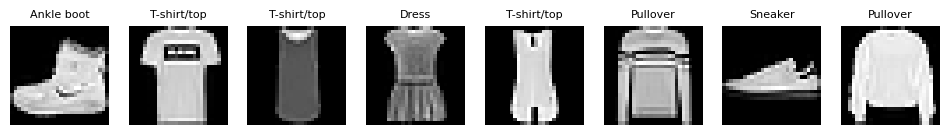

In [4]:
import os

# Which platform? Kaggle has a /kaggle/working folder, Colab has a /content folder
if os.path.isdir("/kaggle/working"):
    where = "Kaggle"
elif os.path.isdir("/content"):
    where = "Google Colab"
else:
    where = "Local machine"
print("Running on:     ", where)
print("Current folder: ", os.getcwd())

from torchvision import datasets
from torchvision import transforms
import matplotlib.pyplot as plt

to_tensor = transforms.ToTensor()      # turns a picture into a tensor of numbers between 0 and 1

fashion = datasets.FashionMNIST(
    root="data",            # folder to save the files in
    train=True,             # the 60,000 training images
    download=True,          # download only if the files are not there yet
    transform=to_tensor)    # convert every image to a tensor

print("Training images:", len(fashion))
print("Classes:        ", fashion.classes)

# Look at the first training image
image, label = fashion[0]
print("Shape of one image:", image.shape)     # [1, 28, 28] = 1 grey channel, 28 x 28 pixels

# Show the first 8 training images with their class names
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i in range(8):
    image, label = fashion[i]
    ax = axes[i]
    ax.imshow(image[0], cmap="gray")          # image[0] drops the channel dimension
    ax.set_title(fashion.classes[label], fontsize=8)
    ax.axis("off")
plt.show()

### Example K2: Titanic Passengers (a Table) from Kaggle Hub
- **What it contains:** 891 passengers of the RMS Titanic, which sank on 15 April 1912, with 12 columns: `PassengerId`, `Survived` (0 = no, 1 = yes), `Pclass` (ticket class 1, 2 or 3), `Name`, `Sex`, `Age`, `SibSp` (siblings and spouses on board), `Parch` (parents and children on board), `Ticket`, `Fare`, `Cabin` and `Embarked` (port: C = Cherbourg, Q = Queenstown, S = Southampton). 342 of the 891 passengers survived (38.4%). Some values are missing: `Age` for 177 passengers, `Cabin` for 687 and `Embarked` for 2. It is the training file of Kaggle's *Titanic - Machine Learning from Disaster* competition.
- **What it is used for:** it is the most famous Kaggle dataset and the usual first Kaggle competition: predict who survived (binary classification). It is also used to practise filling in missing values and building new features, e.g. family size from `SibSp` and `Parch`.
- **Download:** `kagglehub.dataset_download("owner/dataset-name")` downloads any public Kaggle dataset; no login is needed. The name comes from the dataset's URL, here https://www.kaggle.com/datasets/yasserh/titanic-dataset. The CSV file is about 60 KB. On Kaggle you can also click **+ Add Input**, search for the dataset, and its files appear under `/kaggle/input/`.

In [5]:
# kagglehub is pre-installed on Colab and Kaggle.
# On your own machine, install it once with:  uv pip install kagglehub
import os

# Which platform? Kaggle has a /kaggle/working folder, Colab has a /content folder
if os.path.isdir("/kaggle/working"):
    where = "Kaggle"
elif os.path.isdir("/content"):
    where = "Google Colab"
else:
    where = "Local machine"
print("Running on:     ", where)
print("Current folder: ", os.getcwd())

import kagglehub
import pandas as pd

folder = kagglehub.dataset_download("yasserh/titanic-dataset")
print("Downloaded to:", folder)
print("Files:        ", os.listdir(folder))

file_path = os.path.join(folder, "Titanic-Dataset.csv")
titanic = pd.read_csv(file_path)
print("Rows, columns:", titanic.shape)

survived = titanic["Survived"].mean()
print(f"Survival rate: {survived:.1%}")
titanic.head()

Running on:      Kaggle
Current folder:  /kaggle/working
Downloaded to: /kaggle/input/datasets/yasserh/titanic-dataset
Files:         ['Titanic-Dataset.csv']
Rows, columns: (891, 12)
Survival rate: 38.4%


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Example K3: SMS Spam Collection (Text) from Kaggle Hub
- **What it contains:** 5,572 English SMS text messages, each labelled **ham** (a normal message, 4,825) or **spam** (747). Column `v1` is the label and `v2` the text; three more columns are almost empty and the cell drops them. Tiago Almeida and José María Gómez Hidalgo collected the messages in 2011 and published them in the UCI Machine Learning Repository; the Kaggle copy is https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- **What it is used for:** spam detection, the classic first text-classification project (word counts plus a simple classifier such as Naive Bayes, or a small language model). It is also an *imbalanced* dataset: only about 1 message in 7.5 is spam, so a model that always says "ham" is already about 87% accurate.
- **Download:** `kagglehub` downloads one CSV file of about 0.5 MB. The file is not saved as UTF-8 text, so `pd.read_csv()` needs `encoding="latin-1"`.

In [6]:
# kagglehub is pre-installed on Colab and Kaggle.
# On your own machine, install it once with:  uv pip install kagglehub
import os

# Which platform? Kaggle has a /kaggle/working folder, Colab has a /content folder
if os.path.isdir("/kaggle/working"):
    where = "Kaggle"
elif os.path.isdir("/content"):
    where = "Google Colab"
else:
    where = "Local machine"
print("Running on:     ", where)
print("Current folder: ", os.getcwd())

import kagglehub
import pandas as pd

folder = kagglehub.dataset_download("uciml/sms-spam-collection-dataset")
print("Downloaded to:", folder)
print("Files:        ", os.listdir(folder))

file_path = os.path.join(folder, "spam.csv")
sms = pd.read_csv(file_path, encoding="latin-1")   # the file is not UTF-8
sms = sms[["v1", "v2"]]                           # keep the label and the text columns
sms.columns = ["label", "text"]                   # give them clearer names

print("Messages:", len(sms))
print(sms["label"].value_counts())
sms.head()

Running on:      Kaggle
Current folder:  /kaggle/working
Downloaded to: /kaggle/input/datasets/uciml/sms-spam-collection-dataset
Files:         ['spam.csv']
Messages: 5572
label
ham     4825
spam     747
Name: count, dtype: int64


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


# 4. Google Colab vs Kaggle: Compute and Memory, Free and Paid Tiers

<div align="center"><img src="https://github.com/arifpucit/Generative-and-Agentic-AI/blob/main/images/colab-kaggle-04.png?raw=1" width="1500"></div>

| | Colab Free | Colab Pay As You Go | Colab Pro | Colab Pro+ | Kaggle (free) |
|---|---|---|---|---|---|
| **Price** | \$0 | \$9.99 per 100 CU (\$49.99 per 500) | \$9.99 / month | \$49.99 / month | \$0 (no paid plan) |
| **Compute** | Not published, varies | Compute units, valid 90 days | 100 CU / month | 600 CU / month | Weekly quota (about 30 GPU h); +15 h with Colab Pro, +30 h with Pro+ |
| **CPU / RAM** | 2 vCPU, ~12.7 GB | Standard or High-RAM | Standard or High-RAM | Standard or High-RAM | 4 cores, 29 GB (30 GB CPU-only, 330 GB on TPU) |
| **GPU (memory)** | 1 × T4 (15 GB), when available | T4, L4 (24 GB), A100 (40/80 GB), H100 (80 GB), subject to availability | same as Pay As You Go | same as Pay As You Go | 2 × T4 (15 GB each) or 1 × P100 (16 GB) |
| **TPU** | Limited | v2-8, v5e-1, v6e-1 | same | same | TPU v3-8 |
| **Longest session** | At most 12 h | Longer, while compute units last | Longer, while compute units last | Up to 24 h, also with the browser closed | 12 h (9 h on TPU), ends after 20 min idle |
| **Storage that lasts** | Your Google Drive | Your Google Drive | Your Google Drive | Your Google Drive | `/kaggle/working`, 20 GB per version |

*CU = compute units. Colab values on the free tier are what the hardware cell at the top of this notebook printed on a free Colab T4 runtime; Colab does not publish exact limits. Kaggle values are from https://www.kaggle.com/docs/notebooks. Prices and limits checked in November 2026; both platforms change them over time.*

**Which one should I use?**
- **Use Colab** when your files are in Google Drive, when you want to start in seconds with a Google account, or when you need a bigger paid GPU (L4, A100, H100) for a few hours.
- **Use Kaggle** when you need more free memory (29 GB RAM and 2 × 15 GB of GPU memory), when you want a predictable weekly GPU budget, or when your data is a Kaggle dataset or competition.
- **On both:** the machine is temporary. Save your notebook and your results (Drive on Colab, **Save Version** on Kaggle) before the session ends.